In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [69]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
display(df.head())

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Part 1: Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

In [40]:
#Generate a frequency table for the product category.
azm_categories = df['category'].value_counts().head(5)
display(azm_categories)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

Which are the top 5 most listed product categories?
1. Sports & Outdoors
2. Beauty
3. Handmade Clothing, Shoes & Accessories
4. Bath & Body
5. Birthday Gifts

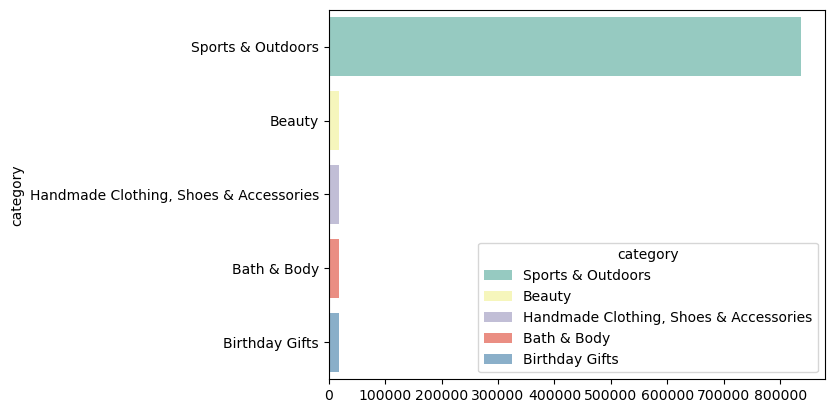

In [42]:
#Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
ax=sns.barplot(y=azm_categories.index, x=azm_categories.values, palette="Set3", hue=azm_categories.index, legend='full')
sns.move_legend(ax, "lower right")

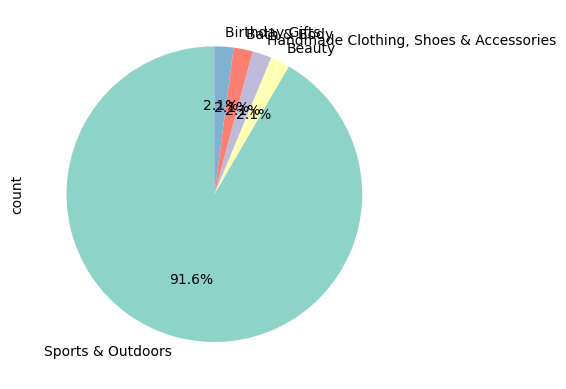

In [52]:
#For a subset of top categories, visualize their proportions using a pie chart.
azm_categories.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"));

Does any category dominate the listings?
Yes, Sports & Outdoors by a very wide margin

Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

In [56]:
#Calculate the mean, median, and mode for the price of products.
print("Mean: ", df['price'].mean())
print("Median: ", df['price'].median())
print("Mode: ", df['price'].mode())

Mean:  89.24380943923663
Median:  19.09
Mode:  0    9.99
Name: price, dtype: float64


What's the average price point of products listed? How does this compare with the most common price point (mode)?
-- The average price is 89 pounds, this is significantly higher than the mode price of 9,99, indicating that there are some outlying high priced items amidst a large amount of cheaply priced items.

In [80]:
#Determine the variance, standard deviation, range, and interquartile range for product price.
round(df['price'].describe(), 2)

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

In [ ]:
How varied are the product prices? Are there any indicators of a significant spread in prices?
High std, low min and high max indicate a significant spread in prices

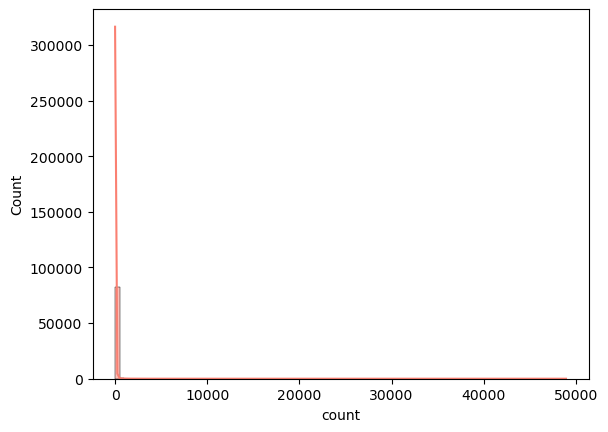

In [89]:
#Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. 
#If its hard to read these diagrams, think why this is, and explain how it could be solved.
sns.histplot(df['price'], kde=True, bins=100, color="salmon");
#this histogram is not clear to read because the high std distorts the values, it could be better viewed if the data was viewed by the lower 50% quantile, or outlying data was removed.

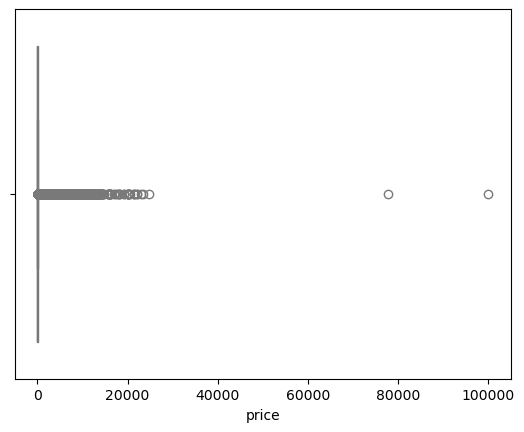

In [92]:
#Are there products that are priced significantly higher than the rest? 
#Use a box plot to showcase the spread and potential outliers in product pricing.
sns.boxplot(x = df['price'], color="lightblue");

Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

In [94]:
#Calculate the mean, median, and mode for the rating of products.
print("Mean: ", df['stars'].mean())
print("Median: ", df['stars'].median())
print("Mode: ", df['stars'].mode())

Mean:  2.152836472966065
Median:  0.0
Mode:  0    0.0
Name: stars, dtype: float64


How do customers generally rate products? Is there a common trend?
Products are generally rated very low, although this data might be thrown off by unrated products having a 0 star rating.

In [102]:
#Determine the variance, standard deviation, and interquartile range for product rating.
round(df['stars'].describe(), 2)

count    2443651.00
mean           2.15
std            2.19
min            0.00
25%            0.00
50%            0.00
75%            4.40
max            5.00
Name: stars, dtype: float64

Are the ratings consistent, or is there a wide variation in customer feedback?
There is a very wide variation. Most products have zero stars, however, the top quartile has a very high rating of 4.4 starts, indicating that perhaps most products have no reviews, but those that have been reviewed are generally rated with four stars or above.

In [113]:
#Calculate the skewness and kurtosis for the rating column.
print("Skew: ", df['stars'].skew())
print("Kurtosis: ", df['stars'].kurtosis())

Skew:  0.08120735761080985
Kurtosis:  -1.9260061280432985


Are the ratings normally distributed, or do they lean towards higher or lower values?
Ratings lean towards lower values

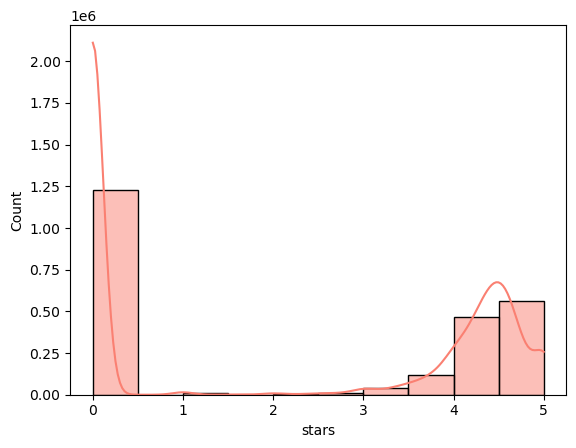

In [106]:
#Plot a histogram to visualize the distribution of product ratings. 
sns.histplot(df['stars'], kde=True, bins=10, color="salmon");

In [ ]:
Is there a specific rating that is more common?
Zero is the most common rating

Summary report:

What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

Sports & Outdoors, Beauty, Handmade Clothing, Shoes & Accessories, Bath & Body, and Birthday Gifts are the most popular product categories on UK Amazon, however, Sports & Outdoors leads by a very large margin (91%), making the other four top categories not statistically very different than those under them. 

How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

The median price of items on amazon is 19,99, however, there are a handful of significantly higher-priced items (max at 100,000 pounds) which increase the average price of all items to 89%. The most common price is 9,99.

How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?
The vasy majority of items are rated with zero starts, this is likely due to new or unrated products having a default rating of zero stars. A wide gap between the minimum rating of zero and the 75% quadtile of 4,40 stars means that though 3/4 of items are not reviewed, those that are reviewed receive quite high ratings of four or five stars.